In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")   # peringatan belum konvergen disembunyikan supaya keluaran bersih

# input dari Data Preparation, fitur sama dengan Random Forest tetapi angkanya diskalakan (ANN peka terhadap skala)
data = pd.read_csv("../data/kbbi_bersih.csv")
data["contoh"] = data["contoh"].fillna("")
data["suku_kata"] = data["nama"].str.count(r"\.") + 1
data["huruf"] = data["nama"].str.replace(".", "", regex=False).str.len()
data["panjang_makna"] = data["submakna"].str.len()
data["jumlah_kata_makna"] = data["submakna"].str.split().str.len()
data["ada_contoh"] = (data["contoh"] != "").astype(int)

train = data[data["split"] == "train"].sample(20000, random_state=42)
test = data[data["split"] == "test"]
y_train, y_test = train["kelas_utama"], test["kelas_utama"]

num_cols = ["suku_kata", "huruf", "panjang_makna", "jumlah_kata_makna", "ada_contoh"]
pre = ColumnTransformer([("angka", MinMaxScaler(), num_cols),
                         ("kata", TfidfVectorizer(max_features=300, min_df=5), "submakna")])
X_train = pre.fit_transform(train)
X_test = pre.transform(test)
print(X_train.shape, X_test.shape)

(20000, 305) (19857, 305)


In [2]:
# arsitektur 3 layer: input layer (satu neuron per fitur), hidden layer 32 neuron, output layer (satu neuron per kelas)
t = time.time()
ann = MLPClassifier(hidden_layer_sizes=(32,), activation="relu", max_iter=100, random_state=42)
ann.fit(X_train, y_train)
waktu_ann = time.time() - t

print(f"Input {X_train.shape[1]} -> Hidden 32 -> Output {len(ann.classes_)}")
print("Bobot input ke hidden:", ann.coefs_[0].shape)
print("Bobot hidden ke output:", ann.coefs_[1].shape)
print(f"Akurasi latih: {accuracy_score(y_train, ann.predict(X_train)):.1%}")
print(f"Akurasi uji: {accuracy_score(y_test, ann.predict(X_test)):.1%}")

Input 305 -> Hidden 32 -> Output 3
Bobot input ke hidden: (305, 32)
Bobot hidden ke output: (32, 3)
Akurasi latih: 85.9%
Akurasi uji: 81.4%


In [3]:
# feedforward manual: satu data dikalikan bobot, diolah fungsi aktivasi, sampai ke output
x = X_test[0].toarray()
hidden = np.maximum(0, x @ ann.coefs_[0] + ann.intercepts_[0])       # aktivasi ReLU
keluar = hidden @ ann.coefs_[1] + ann.intercepts_[1]
proba = np.exp(keluar) / np.exp(keluar).sum()                        # softmax mengubah skor menjadi peluang

print(pd.Series(proba[0], index=ann.classes_).round(3))
print("Sama dengan hasil model:", np.allclose(proba, ann.predict_proba(X_test[0])))
print("Prediksi:", ann.classes_[proba.argmax()], "| Kelas sebenarnya:", y_test.iloc[0])

Adjektiva    0.017
Nomina       0.981
Verba        0.002
dtype: float64
Sama dengan hasil model: True
Prediksi: Nomina | Kelas sebenarnya: Nomina


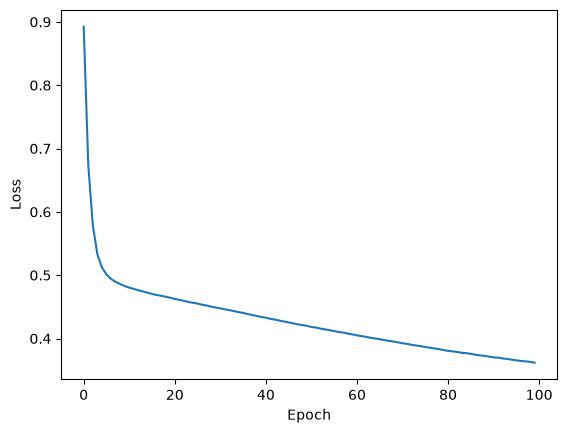

In [4]:
# proses belajar: error (loss) mengecil di setiap epoch hasil backpropagation dan update bobot
plt.plot(ann.loss_curve_)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [5]:
# banyak tombol setelan: jumlah neuron dan jumlah hidden layer (dua hidden layer sudah termasuk deep learning)
hasil = []
for ukuran in [(8,), (32,), (64,), (32, 16)]:
    t = time.time()
    m = MLPClassifier(hidden_layer_sizes=ukuran, max_iter=100, random_state=42).fit(X_train, y_train)
    hasil.append({"Hidden layer": str(ukuran), "Akurasi latih": accuracy_score(y_train, m.predict(X_train)),
                  "Akurasi uji": accuracy_score(y_test, m.predict(X_test)), "Waktu latih (detik)": time.time() - t})
pd.DataFrame(hasil).round(3)

,Hidden layer,Akurasi latih,Akurasi uji,Waktu latih (detik)
0,"(8,)",0.821,0.812,6.152
1,"(32,)",0.859,0.814,7.430
2,"(64,)",0.882,0.815,16.998
3,"(32, 16)",0.880,0.808,10.899


In [6]:
# perbandingan dengan model sebelumnya
model = {"Regresi Logistik": LogisticRegression(max_iter=1000),
         "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
         "ANN": ann}
hasil = []
for nama, m in model.items():
    t = time.time()
    if nama != "ANN":
        m.fit(X_train, y_train)
    hasil.append({"Model": nama, "Akurasi uji": accuracy_score(y_test, m.predict(X_test)),
                  "Waktu latih (detik)": time.time() - t if nama != "ANN" else waktu_ann})
pd.DataFrame(hasil).round(3)

,Model,Akurasi uji,Waktu latih (detik)
0,Regresi Logistik,0.805,0.302
1,Random Forest,0.802,3.211
2,ANN,0.814,7.753


In [7]:
# refleksi: filter spam 3-4-1, bobot dari input "Gratis" dan "Promo" setelah backpropagation
rng = np.random.default_rng(42)
email = pd.DataFrame(rng.integers(0, 2, size=(1000, 3)), columns=["Gratis", "Promo", "Kontak"])
spam = ((email["Gratis"] == 1) | (email["Promo"] == 1)) & (email["Kontak"] == 0)

net = MLPClassifier(hidden_layer_sizes=(4,), max_iter=1, warm_start=True, random_state=0).fit(email, spam)
awal = np.abs(net.coefs_[0]).mean(axis=1)                              # bobot masih acak
net.set_params(max_iter=500).fit(email, spam)
akhir = np.abs(net.coefs_[0]).mean(axis=1)                             # bobot setelah belajar

print(f"Akurasi: {net.score(email, spam):.1%}")
pd.DataFrame({"Bobot awal (rata-rata)": awal, "Bobot akhir (rata-rata)": akhir}, index=email.columns).round(2)

Akurasi: 100.0%


,Bobot awal (rata-rata),Bobot akhir (rata-rata)
Gratis,0.19,0.52
Promo,0.31,0.63
Kontak,0.42,0.96


### Analisis

Pada data KBBI, ANN dengan satu hidden layer berisi 32 neuron mencapai akurasi uji 81,4 persen, sedikit di atas regresi logistik (80,5 persen) dan Random Forest (80,2 persen). Selisihnya hanya sekitar satu poin, sedangkan waktu latih ANN sekitar 5 detik, jauh lebih lama dari regresi logistik yang hanya 0,2 detik. Ini sesuai catatan di materi bahwa ANN kuat menangkap pola rumit tetapi mahal secara komputasi, dan untuk data teks yang sudah cukup rapi seperti ini keuntungannya tidak besar.

Pada tabel arsitektur, menambah neuron dari 8 ke 64 hanya menaikkan akurasi uji dari 81,2 ke 81,5 persen, sementara akurasi latih naik dari 82,1 ke 88,2 persen, yang berarti jarak latih dan uji melebar. Dua hidden layer (32, 16) malah menghasilkan akurasi uji paling rendah (80,8 persen), jadi lebih dalam belum tentu lebih baik. Kurva loss masih menurun di epoch ke-100, jadi pelatihan bisa dilanjutkan, tetapi pengaruhnya pada data uji kecil.

Pada demo filter spam 3-4-1, bobot dari ketiga input menguat setelah training. Rata-rata bobot Gratis naik dari 0,19 menjadi 0,52 dan Promo dari 0,31 menjadi 0,63, sesuai jawaban refleksi di materi. Bobot Kontak naik paling besar (0,42 menjadi 0,96) karena pada data buatan ini pengirim yang dikenal juga menentukan apakah email dianggap spam.